# CMPS261 Project - Amazon Shopping Queries (ESCI)
Mazen Hachem, Ram Haidar, Karim Nabaa

The goal is to predict if a product is Exact (E), Substitute (S), Complement (C) or Irrelevant (I) for a search query.

- Part 1: data + preprocessing (Mazen)
- Part 2: baselines, TF-IDF + logistic regression and boosted trees (Ram)
- Part 3: fine-tuning a small BERT model (Karim)
- Part 4: final test results and comparing the models



Metrics: we mainly look at macro F1 because the classes are very unbalanced. We also report accuracy,
F1 for each class and nDCG (how good the ranking of products is for each query, using the ESCI gains
E=1, S=0.1, C=0.01, I=0). All the choices are made on validation, the test set is only used in Part 4.


## 0. Setup
install rapidfuzz and download the dataset from the amazon github (around 1.2GB)

In [1]:
!pip -q install rapidfuzz

In [2]:
import urllib.request
from pathlib import Path

RAW = Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)
URL = "https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset/"
for f in ["shopping_queries_dataset_examples.parquet", "shopping_queries_dataset_products.parquet"]:
    if not (RAW / f).exists():
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, RAW / f)
    print(f, f"{(RAW / f).stat().st_size / 1e6:.0f} MB")

downloading shopping_queries_dataset_examples.parquet
shopping_queries_dataset_examples.parquet 51 MB
downloading shopping_queries_dataset_products.parquet
shopping_queries_dataset_products.parquet 1109 MB


In [3]:
import copy
import gc
import html
import re
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import scipy.sparse as sp
import torch
from rapidfuzz import fuzz
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ndcg_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

PROCESSED, RESULTS, MODELS = Path("data/processed"), Path("results"), Path("models")
for d in (PROCESSED, RESULTS, MODELS):
    d.mkdir(parents=True, exist_ok=True)
for old in RESULTS.glob("*_results.csv"):
    old.unlink()

SEED = 42
LABELS = ["E", "S", "C", "I"]  # Exact, Substitute, Complement, Irrelevant
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
GAINS = {"E": 1.0, "S": 0.1, "C": 0.01, "I": 0.0}
GAIN_VEC = np.array(list(GAINS.values()))

### Helper functions
we use the same functions to evaluate all the models so the results are comparable

In [4]:
def load_split(name):
    return pd.read_parquet(PROCESSED / f"{name}.parquet")


def ndcg_per_query(query_ids, true_labels, scores):
    df = pd.DataFrame({"q": np.asarray(query_ids), "g": [GAINS[l] for l in true_labels], "s": np.asarray(scores)})
    out = []
    for _, grp in df.groupby("q", sort=False):
        g = grp["g"].to_numpy()
        if g.max() <= 0:
            continue
        if len(g) == 1:
            out.append(1.0)
        else:
            out.append(ndcg_score(g[None, :], grp["s"].to_numpy()[None, :], ignore_ties=False))
    return float(np.mean(out))


def predict_labels(proba, offsets=None):
    proba = np.asarray(proba)
    if offsets is None:
        return proba.argmax(1)
    return (np.log(proba + 1e-9) + offsets).argmax(1)


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=range(4), zero_division=0)


def evaluate(df, proba, name, offsets=None):
    y_true = df["esci_label"].map(LABEL2ID).to_numpy()
    y_pred = predict_labels(proba, offsets)
    res = {
        "model": name,
        "macro-F1": macro_f1(y_true, y_pred),
        "accuracy (micro-F1)": accuracy_score(y_true, y_pred),
        "nDCG": ndcg_per_query(df["query_id"], df["esci_label"], np.asarray(proba) @ GAIN_VEC),
    }
    for l, f in zip(LABELS, f1_score(y_true, y_pred, average=None, labels=range(4), zero_division=0)):
        res[f"F1_{l}"] = f
    return res


def report(df, proba, offsets=None):
    y_true = df["esci_label"].map(LABEL2ID).to_numpy()
    y_pred = predict_labels(proba, offsets)
    print(classification_report(y_true, y_pred, labels=range(4), target_names=LABELS, digits=3, zero_division=0))
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=range(4)), index=[f"true_{l}" for l in LABELS],
                        columns=[f"pred_{l}" for l in LABELS])


def tune_offsets(df, proba, grid=np.linspace(-3, 3, 25), rounds=2):
    y = df["esci_label"].map(LABEL2ID).to_numpy()
    logp = np.log(np.asarray(proba) + 1e-9)
    off = np.zeros(4)
    best = macro_f1(y, logp.argmax(1))
    for _ in range(rounds):
        for c in range(1, 4):
            for v in grid:
                o = off.copy()
                o[c] = v
                s = macro_f1(y, (logp + o).argmax(1))
                if s > best:
                    best, off = s, o
    return off


def save_result(res, split):
    path = RESULTS / f"{split}_results.csv"
    df = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["model"])
    df = pd.concat([df[df.model != res["model"]], pd.DataFrame([res])], ignore_index=True)
    df.to_csv(path, index=False)

---
# Part 1 - Data and preprocessing (Mazen)

Some choices we made:
- we only kept the English (us) queries since the BERT model we use is English
- we used the large version of the dataset, which is the one for the 4 class task
- the test set is from the official test split, and validation is taken from the train split
- we split train and validation by query so the same query is never in both, otherwise the model could
  just memorize queries and the validation score would be too high
- the full data is too big for Colab memory so we sample queries (we keep all the products of a query
  because nDCG is computed per query)

In [5]:
N_TRAIN_Q, N_VAL_Q, N_TEST_Q = 20_000, 3_000, 4_000  # number of queries (not rows)

examples = pd.read_parquet(RAW / "shopping_queries_dataset_examples.parquet")
print(examples.shape)
examples.head()

(2621288, 9)


,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [6]:
ex = examples[(examples.product_locale == "us") & (examples.large_version == 1)].copy()
del examples
print(f"US / large version: {len(ex):,} pairs, {ex.query_id.nunique():,} queries")
print(ex.split.value_counts())

US / large version: 1,818,825 pairs, 97,345 queries
split
train    1393063
test      425762
Name: count, dtype: int64


### 1.1 EDA (on the official train split only, we don't look at the test labels)

{'E': 0.696, 'S': 0.197, 'C': 0.021, 'I': 0.086}
pairs per query: {'count': 74888.0, 'mean': 18.6, 'std': 7.9, 'min': 3.0, '25%': 16.0, '50%': 16.0, '75%': 16.0, 'max': 198.0}
query length (words): {'count': 74888.0, 'mean': 3.5, 'std': 1.6, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 29.0}


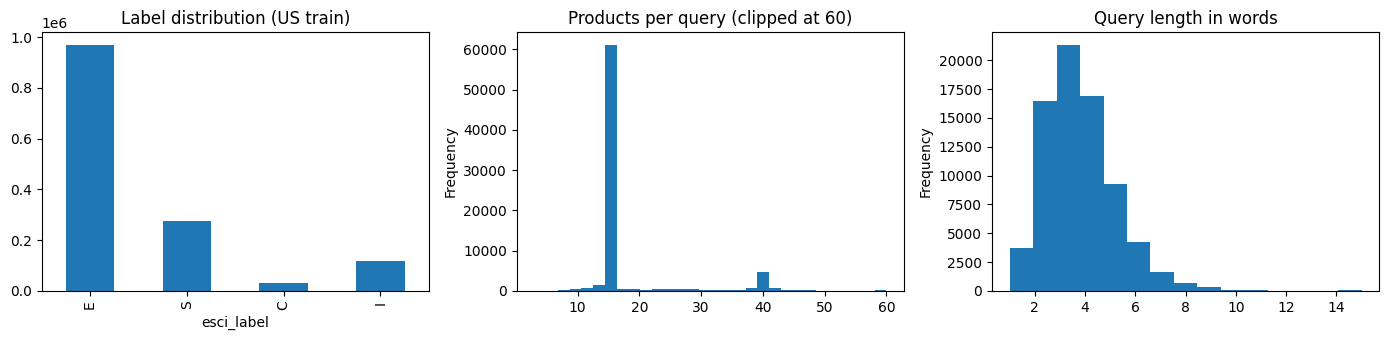

In [7]:
eda = ex[ex.split == "train"]
print(eda.esci_label.value_counts(normalize=True)[LABELS].round(3).to_dict())

pairs_per_q = eda.groupby("query_id").size()
q_len = eda.drop_duplicates("query_id")["query"].str.split().str.len()
print("pairs per query:", pairs_per_q.describe().round(1).to_dict())
print("query length (words):", q_len.describe().round(1).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
eda.esci_label.value_counts()[LABELS].plot.bar(ax=ax[0], title="Label distribution (US train)")
pairs_per_q.clip(upper=60).plot.hist(bins=30, ax=ax[1], title="Products per query (clipped at 60)")
q_len.clip(upper=15).plot.hist(bins=15, ax=ax[2], title="Query length in words")
plt.tight_layout()
plt.savefig(RESULTS / "eda.png", dpi=150)
plt.show()
del eda

The labels are really unbalanced, around 70% are Exact and only 2% Complement. So if a model always says Exact it
already gets 70% accuracy, that's why we use macro F1 as our main metric.

### 1.2 Sampling queries and making the splits
a few query ids are in both official splits, we remove them from the train side so they can't leak into test

In [8]:
rng = np.random.default_rng(SEED)
train_q_all = ex.loc[ex.split == "train", "query_id"].unique()
test_q_all = ex.loc[ex.split == "test", "query_id"].unique()
shared = np.intersect1d(train_q_all, test_q_all)
print("query ids in both official splits:", len(shared))
train_q_all = np.setdiff1d(train_q_all, shared)

picked = rng.choice(train_q_all, N_TRAIN_Q + N_VAL_Q, replace=False)
train_q, val_q = picked[:N_TRAIN_Q], picked[N_TRAIN_Q:]
test_q = rng.choice(test_q_all, N_TEST_Q, replace=False)

parts = {
    "train": ex[(ex.split == "train") & ex.query_id.isin(train_q)],
    "val": ex[(ex.split == "train") & ex.query_id.isin(val_q)],
    "test": ex[(ex.split == "test") & ex.query_id.isin(test_q)],
}
for k, v in parts.items():
    print(f"{k:5s}: {len(v):7,} pairs, {v.query_id.nunique():6,} queries")

norm = lambda d: set(d["query"].str.lower().str.split().str.join(" "))
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(parts[a].query_id).isdisjoint(parts[b].query_id), f"query leakage {a}/{b}"
    print(f"{a}/{b}: same query text in both = {len(norm(parts[a]) & norm(parts[b]))}")

query ids in both official splits: 1
train: 373,188 pairs, 20,000 queries
val  :  55,065 pairs,  3,000 queries
test :  76,226 pairs,  4,000 queries
train/val: same query text in both = 0
train/test: same query text in both = 0
val/test: same query text in both = 0


### 1.3 Adding the product info and cleaning
the products file is big (1GB) so we only load the US products and the columns we need

In [9]:
needed = set(pd.concat(parts.values()).product_id)
products = pq.read_table(
    RAW / "shopping_queries_dataset_products.parquet",
    columns=["product_id", "product_locale", "product_title", "product_brand", "product_color",
             "product_bullet_point", "product_description"],
    filters=[("product_locale", "=", "us")],
).to_pandas()
products = products[products.product_id.isin(needed)].drop(columns="product_locale")
print(products.shape)
print("missing values (%):")
print((products.isna().mean() * 100).round(1))

(418740, 6)
missing values (%):
product_id               0.0
product_title            0.0
product_brand            5.2
product_color           31.6
product_bullet_point    13.1
product_description     48.6
dtype: float64


In [10]:
TAG = re.compile(r"<[^>]+>")
SPACE = re.compile(r"\s+")


def clean(text):
    if not isinstance(text, str):
        return ""
    text = html.unescape(TAG.sub(" ", text))
    return SPACE.sub(" ", text).strip()


for col in ["product_title", "product_brand", "product_color", "product_bullet_point", "product_description"]:
    products[col] = products[col].map(clean)

for name, df in parts.items():
    df = df[["example_id", "query_id", "query", "product_id", "esci_label"]].merge(
        products, on="product_id", how="left", validate="many_to_one")
    df["query"] = df["query"].map(clean)
    df = df.fillna("")
    df.to_parquet(PROCESSED / f"{name}.parquet", index=False)
    print(name, df.shape, "label share:", df.esci_label.value_counts(normalize=True)[LABELS].round(3).to_dict())

del ex, parts, products
gc.collect()

train (373188, 10) label share: {'E': 0.699, 'S': 0.195, 'C': 0.02, 'I': 0.085}
val (55065, 10) label share: {'E': 0.7, 'S': 0.195, 'C': 0.021, 'I': 0.085}
test (76226, 10) label share: {'E': 0.644, 'S': 0.226, 'C': 0.026, 'I': 0.104}


97

### 1.4 Hard examples
Here we look at products labeled Irrelevant even though the title has all the words of the query.
We think these will be hard for TF-IDF since it only looks at matching words.

In [11]:
train, val, test = load_split("train"), load_split("val"), load_split("test")


def overlap(q, t):
    q, t = set(q.lower().split()), set(t.lower().split())
    return len(q & t) / max(len(q), 1)


train_overlap = np.array([overlap(q, t) for q, t in zip(train["query"], train.product_title)])
print("mean fraction of query words in title, per label:")
print(pd.Series(train_overlap).groupby(train.esci_label.values).mean()[LABELS].round(3))
train.loc[(train.esci_label == "I") & (train_overlap >= 0.99), ["query", "product_title"]].head(10)

mean fraction of query words in title, per label:
E    0.542
S    0.337
C    0.433
I    0.220
dtype: float64


,query,product_title
6662,100% leather couch,HOMFINER Faux Leather and 100% Cotton Decorati...
6663,100% leather couch,DEZENE Faux Leather with 100% Cotton Decorativ...
6664,100% leather couch,Texture + Ink Boho Pillow Covers Throw Pillow ...
8770,12v pa system,Universal Power Group 12V 5AH SLA Battery Repl...
8771,12v pa system,Power Home HiFi Stereo Amplifier - 90 Watt Por...
10729,2 gallon water bottle,"5 Gallon Water Dispenser,Electric Drinking Wat..."
11218,2 tier bathroom shelf,"2 Tier Bathroom Organizer Countertop Holder, B..."
11801,20x25x4 filter honeywell,Honeywell Home Air Filter Ultra Efficiency CF2...
12201,23mm socket,Urrea 7023M 3/8-Inch Drive Deep 6-Point 23mm I...
19195,6s iphone case,"KUMEEK iPhone 6s Plus Case/iPhone 6 Plus Case,..."


---
# Part 2 - Baselines (Ram)

Model 1 is TF-IDF + logistic regression. If we just do TF-IDF on the query and title
together the model can't really know if they match, so we give it 3 things: TF-IDF of the query, TF-IDF of
the title, and the two multiplied together.
We also add some similarity features.

Model 2 is gradient boosted trees on features we made by hand.

In this part we only look at validation. The test predictions are saved and scored in Part 4.

In [12]:
y_train = train.esci_label.map(LABEL2ID).to_numpy()
y_val = val.esci_label.map(LABEL2ID).to_numpy()
print(len(train), len(val), len(test))

373188 55065 76226


### 2.1 Hand made features (used in both models)
21 features. The last 3 are new, they try to catch the "word trap": the title has all the query words but it's a
different model, like "6s iphone case" and a case for the 6s **plus**.

In [13]:
TOKEN = re.compile(r"[a-z0-9]+")
VARIANTS = {"plus", "pro", "max", "mini", "lite", "ultra", "air", "se", "xl", "xxl", "xs", "xr", "slim", "kids", "junior"}


def toks(s):
    return TOKEN.findall(s.lower())


def frac_in(q, field):
    # what fraction of the query words are in this field
    return len(q & field) / len(q) if q else 0.0


def has_digit(t):
    return any(ch.isdigit() for ch in t)


def lexical_features(df):
    rows = []
    for q, title, brand, color, bullets, desc in zip(df["query"], df.product_title, df.product_brand,
                                                     df.product_color, df.product_bullet_point, df.product_description):
        qt = toks(q)
        q_set, t_set = set(qt), set(toks(title))
        b_set, d_set = set(toks(bullets)), set(toks(desc))
        brand_l, color_l = brand.lower(), color.lower()
        nums = {t for t in q_set if t.isdigit()}
        q_models = {t for t in q_set if has_digit(t)}  
        t_models = {t for t in t_set if has_digit(t)}
        rows.append({
            "q_len": len(qt),
            "t_len": len(t_set),
            "q_in_title": frac_in(q_set, t_set),
            "q_in_bullets": frac_in(q_set, b_set),
            "q_in_desc": frac_in(q_set, d_set),
            "q_in_any": frac_in(q_set, t_set | b_set | d_set | set(toks(brand))),
            "jaccard_title": len(q_set & t_set) / max(len(q_set | t_set), 1),
            "first_tok_in_title": float(bool(qt) and qt[0] in t_set),
            "last_tok_in_title": float(bool(qt) and qt[-1] in t_set),  # the last word is usually the type of product
            "fuzz_partial": fuzz.partial_ratio(q.lower(), title.lower()) / 100,
            "fuzz_token_set": fuzz.token_set_ratio(q.lower(), title.lower()) / 100,
            "brand_in_query": float(bool(brand_l) and brand_l in q.lower()),
            "brand_missing": float(not brand_l),
            "color_in_query": float(bool(color_l) and color_l in q.lower()),
            "q_has_number": float(bool(nums)),
            "numbers_in_title": frac_in(nums, t_set) if nums else -1.0,
            "bullets_missing": float(not bullets),
            "desc_missing": float(not desc),
            # new word trap features
            "q_models_in_title": frac_in(q_models, t_set) if q_models else -1.0,
            "title_extra_models": min(len(t_models - q_set), 5),  # model numbers in the title that are not in the query
            "title_extra_variant": len((t_set & VARIANTS) - q_set),  
        })
    return pd.DataFrame(rows)


t0 = time.time()
F_train, F_val, F_test = (lexical_features(d) for d in (train, val, test))
print(f"lexical features: {F_train.shape[1]} columns, {time.time() - t0:.0f}s")
F_train.assign(label=train.esci_label.values).groupby("label").mean().loc[LABELS].T.round(3)

lexical features: 21 columns, 57s


label,E,S,C,I
q_len,3.471,3.894,3.543,4.054
t_len,16.638,16.077,16.556,15.052
q_in_title,0.632,0.405,0.487,0.263
q_in_bullets,0.457,0.322,0.399,0.224
q_in_desc,0.279,0.184,0.250,0.137
q_in_any,0.731,0.506,0.604,0.373
jaccard_title,0.138,0.097,0.100,0.064
first_tok_in_title,0.647,0.335,0.540,0.276
last_tok_in_title,0.613,0.456,0.423,0.254
fuzz_partial,0.710,0.603,0.648,0.539


### 2.2 TF-IDF
we fit one vectorizer on train only and use it for both query and title so the same word has the same column

In [14]:
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=100_000, sublinear_tf=True)
tfidf.fit(pd.concat([train["query"], train.product_title + " " + train.product_brand]))


def tfidf_blocks(df):
    Q = tfidf.transform(df["query"])
    T = tfidf.transform(df.product_title + " " + df.product_brand)
    QT = Q.multiply(T).tocsr()
    cos = np.asarray(QT.sum(1))  
    return Q, T, QT, cos


blocks = {"train": tfidf_blocks(train), "val": tfidf_blocks(val), "test": tfidf_blocks(test)}
scaler = StandardScaler().fit(np.hstack([F_train, blocks["train"][3]]))


def logreg_matrix(name, F):
    Q, T, QT, cos = blocks[name]
    dense = sp.csr_matrix(scaler.transform(np.hstack([F, cos])))
    return sp.hstack([Q, T, QT, dense]).tocsr()


X_train, X_val, X_test = logreg_matrix("train", F_train), logreg_matrix("val", F_val), logreg_matrix("test", F_test)
print(X_train.shape)

(373188, 300022)


### 2.3 TF-IDF + Logistic Regression
we try different C values, with and without class_weight="balanced" and pick the best one on validation using macro F1

In [15]:
lr_runs, best_f1 = [], -1
for cw in [None, "balanced"]:
    for C in [0.1, 0.3, 1.0, 3.0]:
        t0 = time.time()
        m = LogisticRegression(C=C, class_weight=cw, max_iter=300, random_state=SEED).fit(X_train, y_train)
        r = evaluate(val, m.predict_proba(X_val), f"LogReg C={C} cw={cw}")
        r.update(C=C, class_weight=str(cw), fit_s=time.time() - t0)
        lr_runs.append(r)
        print(f"C={C:<4} cw={str(cw):9s} macro-F1={r['macro-F1']:.4f} acc={r['accuracy (micro-F1)']:.4f} "
              f"nDCG={r['nDCG']:.4f} ({r['fit_s']:.0f}s)")
        if r["macro-F1"] > best_f1:  # keep the best model so we don't have to train it again
            best_f1, logreg = r["macro-F1"], m

lr_runs = pd.DataFrame(lr_runs).sort_values("macro-F1", ascending=False)
lr_runs.to_csv(RESULTS / "tuning_logreg.csv", index=False)
lr_runs.head()

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C=0.1  cw=None      macro-F1=0.3551 acc=0.7219 nDCG=0.9400 (161s)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C=0.3  cw=None      macro-F1=0.3639 acc=0.7189 nDCG=0.9397 (158s)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C=1.0  cw=None      macro-F1=0.3697 acc=0.7112 nDCG=0.9384 (163s)


... (7 outputs left out)

C=1.0  cw=balanced  macro-F1=0.4134 acc=0.6403 nDCG=0.9380 (161s)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


C=3.0  cw=balanced  macro-F1=0.4138 acc=0.6399 nDCG=0.9378 (166s)


,model,macro-F1,accuracy (micro-F1),nDCG,F1_E,F1_S,F1_C,F1_I,C,class_weight,fit_s
5,LogReg C=0.3 cw=balanced,0.421711,0.635413,0.939678,0.782525,0.392236,0.163805,0.348279,0.3,balanced,160.491009
4,LogReg C=0.1 cw=balanced,0.421325,0.621901,0.939804,0.772982,0.395895,0.157371,0.359052,0.1,balanced,161.607920
7,LogReg C=3.0 cw=balanced,0.413756,0.639916,0.937764,0.787209,0.380731,0.152351,0.334734,3.0,balanced,166.439364
6,LogReg C=1.0 cw=balanced,0.413374,0.640280,0.938046,0.787055,0.386434,0.149254,0.330755,1.0,balanced,161.117501
3,LogReg C=3.0 cw=None,0.371624,0.706529,0.937653,0.832337,0.325893,0.034755,0.293513,3.0,None,165.748996


In [16]:
p_val_lr = logreg.predict_proba(X_val)
p_test_lr = logreg.predict_proba(X_test)  # saved for Part 4
save_result(evaluate(val, p_val_lr, "TF-IDF + LogReg"), "val")
print("best:", lr_runs.iloc[0].model)
report(val, p_val_lr)

best: LogReg C=0.3 cw=balanced
              precision    recall  f1-score   support

           E      0.840     0.732     0.783     38524
           S      0.380     0.406     0.392     10732
           C      0.120     0.256     0.164      1135
           I      0.281     0.458     0.348      4674

    accuracy                          0.635     55065
   macro avg      0.405     0.463     0.422     55065
weighted avg      0.688     0.635     0.657     55065



,pred_E,pred_S,pred_C,pred_I
true_E,28203,5663,1458,3200
true_S,3824,4355,463,2090
true_C,479,180,291,185
true_I,1052,1276,206,2140


Which words are most important for each class?

In [17]:
vocab = np.array(tfidf.get_feature_names_out())
V = len(vocab)
for i, lab in enumerate(LABELS):
    coef = logreg.coef_[i, 2 * V:3 * V]
    print(lab, ":", ", ".join(vocab[np.argsort(coef)[-12:][::-1]]))

E : case, socks, iphone plus, brush, tape, 3m, holder, kit, кроссовки, charger, shorts, adapter
S : maxpedition, boombah, socks, lifeguard, furious, bracelet, backpack, earrings, pikolinos, shampoo, eqyss, home alone
C : tottenham, nakamichi, wallmart, landwave, ring, dollhouse, iv, snaptain, miraculous, zipp, wacom, rikon
I : champion, otterbox, columbia, fleshlight, fiskars, leupold, valken, queenieke, nattork, upright, timeless, petrol


Moving the decision boundary: the model gives probabilities and we pick the biggest one. For the small
classes it can help to add a small offset before picking based on validation.

In [18]:
off_lr = tune_offsets(val, p_val_lr)
print("offsets (E, S, C, I):", off_lr.round(2))
save_result(evaluate(val, p_val_lr, "TF-IDF + LogReg + offsets", off_lr), "val")
report(val, p_val_lr, off_lr)

offsets (E, S, C, I): [ 0.   -0.25 -0.25 -0.75]
              precision    recall  f1-score   support

           E      0.820     0.803     0.812     38524
           S      0.394     0.410     0.402     10732
           C      0.127     0.241     0.166      1135
           I      0.362     0.311     0.335      4674

    accuracy                          0.673     55065
   macro avg      0.426     0.441     0.429     55065
weighted avg      0.684     0.673     0.678     55065



,pred_E,pred_S,pred_C,pred_I
true_E,30944,4975,1210,1395
true_S,4815,4398,440,1079
true_C,590,186,274,85
true_I,1382,1597,240,1455


In [19]:
del X_train, X_val, X_test, blocks
gc.collect()

0

### 2.4 Gradient boosted trees
we try 8 combinations of parameters. In the first run we used early stopping, but that takes a random 10% of the
rows as holdout. Now we just try a fixed number of trees and choose on
our validation set. class_weight="balanced" was always better on macro F1 in the first run so we keep it.

In [20]:
F_train["tfidf_cos"] = tfidf_blocks(train)[3].ravel()
F_val["tfidf_cos"] = tfidf_blocks(val)[3].ravel()
F_test["tfidf_cos"] = tfidf_blocks(test)[3].ravel()

grid = [
    dict(learning_rate=lr, max_leaf_nodes=leaves, max_iter=n)
    for lr in [0.05, 0.1] for leaves in [31, 63] for n in [200, 400]
]

gb_runs, best_f1 = [], -1
for i, params in enumerate(grid):
    t0 = time.time()
    m = HistGradientBoostingClassifier(early_stopping=False, l2_regularization=1.0, class_weight="balanced",
                                       random_state=SEED, **params).fit(F_train, y_train)
    r = evaluate(val, m.predict_proba(F_val), f"GBT config {i}")
    r.update(params, fit_s=time.time() - t0, config=i)
    gb_runs.append(r)
    print(f"macro-F1={r['macro-F1']:.4f} acc={r['accuracy (micro-F1)']:.4f} {params} ({r['fit_s']:.0f}s)")
    if r["macro-F1"] > best_f1:
        best_f1, gbt = r["macro-F1"], m

gb_runs = pd.DataFrame(gb_runs).sort_values("macro-F1", ascending=False)
gb_runs.to_csv(RESULTS / "tuning_gbt.csv", index=False)
gb_runs.head()

macro-F1=0.3690 acc=0.5079 {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 200} (30s)
macro-F1=0.3723 acc=0.5177 {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'max_iter': 400} (52s)
macro-F1=0.3727 acc=0.5223 {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'max_iter': 200} (34s)
macro-F1=0.3763 acc=0.5351 {'learning_rate': 0.05, 'max_leaf_nodes': 63, 'max_iter': 400} (59s)
macro-F1=0.3704 acc=0.5169 {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'max_iter': 200} (27s)
macro-F1=0.3715 acc=0.5276 {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'max_iter': 400} (48s)
macro-F1=0.3728 acc=0.5308 {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'max_iter': 200} (31s)
macro-F1=0.3751 acc=0.5498 {'learning_rate': 0.1, 'max_leaf_nodes': 63, 'max_iter': 400} (55s)


,model,macro-F1,accuracy (micro-F1),nDCG,F1_E,F1_S,F1_C,F1_I,learning_rate,max_leaf_nodes,max_iter,fit_s,config
3,GBT config 3,0.376280,0.535113,0.938145,0.690318,0.390851,0.067096,0.356857,0.05,63,400,59.231474,3
7,GBT config 7,0.375084,0.549823,0.937020,0.704708,0.387196,0.062203,0.346228,0.10,63,400,55.227792,7
6,GBT config 6,0.372777,0.530755,0.938038,0.686173,0.388782,0.065332,0.350822,0.10,63,200,30.666642,6
2,GBT config 2,0.372691,0.522292,0.938490,0.678265,0.388333,0.068211,0.355953,0.05,63,200,33.822993,2
1,GBT config 1,0.372294,0.517715,0.937956,0.673091,0.389605,0.069639,0.356842,0.05,31,400,51.624765,1


In [21]:
p_val_gb = gbt.predict_proba(F_val)
p_test_gb = gbt.predict_proba(F_test)  # saved for Part 4
save_result(evaluate(val, p_val_gb, "Lexical features + GBT"), "val")
report(val, p_val_gb)

              precision    recall  f1-score   support

           E      0.892     0.563     0.690     38524
           S      0.333     0.473     0.391     10732
           C      0.039     0.225     0.067      1135
           I      0.271     0.524     0.357      4674

    accuracy                          0.535     55065
   macro avg      0.384     0.446     0.376     55065
weighted avg      0.713     0.535     0.591     55065



,pred_E,pred_S,pred_C,pred_I
true_E,21686,8595,4423,3820
true_S,1767,5075,1325,2565
true_C,334,324,255,222
true_I,518,1243,463,2450


Which features does the tree model use the most?

In [22]:
from sklearn.inspection import permutation_importance

sub = np.random.default_rng(SEED).choice(len(F_val), min(20_000, len(F_val)), replace=False)
imp = permutation_importance(gbt, F_val.iloc[sub], y_val[sub], scoring="f1_macro", n_repeats=3, random_state=SEED)
pd.Series(imp.importances_mean, index=F_val.columns).sort_values(ascending=False).round(4).head(12)

fuzz_partial          0.0304
q_in_any              0.0304
q_models_in_title     0.0155
tfidf_cos             0.0142
first_tok_in_title    0.0115
fuzz_token_set        0.0106
q_in_title            0.0056
jaccard_title         0.0054
t_len                 0.0042
title_extra_models    0.0038
q_has_number          0.0035
last_tok_in_title     0.0034
dtype: float64

In [23]:
joblib.dump({"tfidf": tfidf, "scaler": scaler, "logreg": logreg, "offsets": off_lr}, MODELS / "tfidf_logreg.joblib")
joblib.dump(gbt, MODELS / "lexical_gbt.joblib")

['models/lexical_gbt.joblib']

---
# Part 3 - BERT model (Karim)
Karim will add his part here (and part 4)